# The five steps of a round

> Why a round is divided this way, and who decides what

::: {.callout-note appearance="simple" icon=false}
**Explanation: understand why.** Read it away from the work. There is nothing to run. Want to act? Use a [how-to guide](../how-to/02_use_your_data.ipynb). [About the four kinds of page](../explanation/06_documentation.ipynb).
:::

You cannot sample everywhere, and you don't know where it matters until you have sampled. trufl's answer to this circle is to spend the budget in rounds. Each round acts on what is known, and what it finds changes the next.

The maps show what that does. The first round follows the survey. The second follows the survey and 600 measurements, and goes elsewhere.

In [ ]:
#| hide
import warnings
warnings.filterwarnings('ignore')

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import geopandas as gpd
from fastcore.test import test_eq

from trufl.utils import gridder
from trufl.callbacks import State, MaxCB, MinCB, StdCB, CountCB, PriorCB
from trufl.optimizer import Optimizer
from trufl.sampler import Sampler, rank_to_sample
from trufl.collector import DataCollector

fname_raster = '../files/ground-truth-01-4326-simulated.tif'
areas = gridder(fname_raster)
no_samples = gpd.GeoDataFrame(index=pd.Index([], name='loc_id'), geometry=None, data={'value': None})
prior_state = State(no_samples, areas, cbs=[PriorCB(fname_raster)])()
first_ranks = Optimizer(prior_state).get_rank(is_benefit_x=[True], w_vector=[1], s_method='CP')
first_n = rank_to_sample(first_ranks['rank'].reindex(areas.index).to_numpy(), budget=600, min=1, policy='quantiles')
measurements = DataCollector(fname_raster).collect(
    Sampler(areas).sample(first_n, method='uniform', rng=np.random.default_rng(0)))
state = State(measurements, areas, cbs=[MaxCB(), MinCB(), StdCB(), CountCB(), PriorCB(fname_raster)])()
ranks = Optimizer(state).get_rank(is_benefit_x=[True, True, True, False, True],
                                  w_vector=[0.25, 0.125, 0.125, 0.25, 0.25], n_method='LINEAR1', s_method='CP')

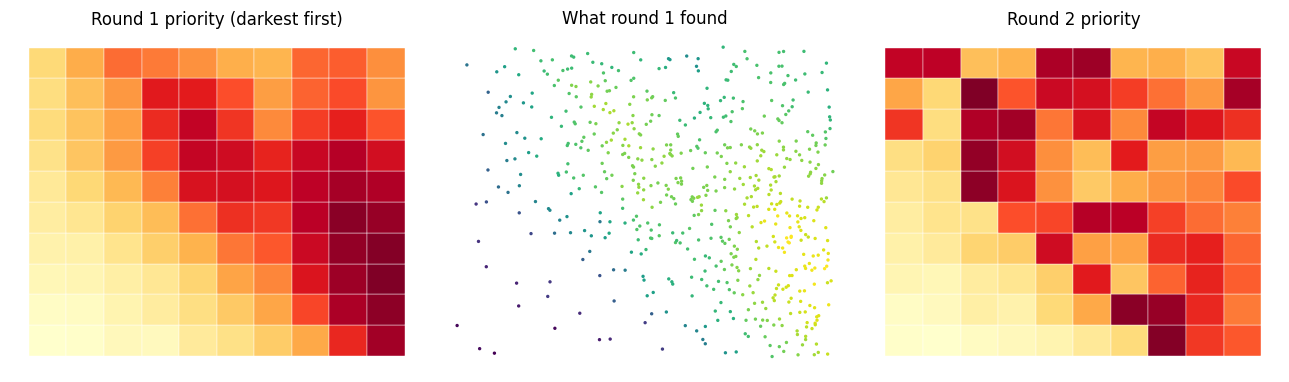

In [ ]:
#| echo: false
fig, axs = plt.subplots(1, 3, figsize=(13, 3.8))
areas.join(first_ranks).plot(column='rank', cmap='YlOrRd_r', ax=axs[0], edgecolor='white', lw=0.3)
measurements.plot(column='value', markersize=2, ax=axs[1])
areas.join(ranks).plot(column='rank', cmap='YlOrRd_r', ax=axs[2], edgecolor='white', lw=0.3)
for ax, title in zip(axs, ('Round 1 priority (darkest first)', 'What round 1 found', 'Round 2 priority')):
    ax.set_title(title)
    ax.set_axis_off()
plt.tight_layout()

## Five questions, kept apart

It would be possible to go straight from a map to a list of points. trufl doesn't, because five different questions hide in that jump, and different people can answer them.

| Step | The question | Who can answer it |
|---|---|---|
| Describe | What do we know about each area? | Those who hold the data |
| Rank | What matters most? | Those who answer for the decision |
| Allocate | How much can we afford, and how concentrated? | Those who hold the budget |
| Place | Where can people actually go? | Those who know the ground |
| Measure | Are the results comparable? | The field and laboratory teams |

Keeping them apart makes a plan open to challenge. Someone who disagrees can say *which* answer they dispute: the data, the priority, the budget or the ground.

## Describe

Everything trufl will consider has to become a column of one table, the state. This is a strength, because the whole basis of a plan fits on a page. It is also the biggest blind spot: a concern that has no column does not exist for the four steps that follow.

## Rank

Ranking is where facts meet values. The highest measured value is a fact. That it matters twice as much as the population is a choice. trufl asks for that choice as a number, so that it is visible.

## Allocate

An order of priority does not say how hard to follow it. All samples could go to the first area, or be spread almost evenly. Allocation makes that second choice separately, so that the priorities can stay the same when the budget changes.

## Place

Up to here an area is one row in a table. At this step it becomes ground, with roads, water, owners and danger, about which trufl knows only the outline.

## Measure

The round ends by changing what is known, which is its whole purpose. It is also where errors enter unseen, because a measurement in another unit or from another depth looks like any other number.

## Why the unit is the area

trufl decides per area, such as a municipality, because decisions after an accident are often taken and announced that way. The price is that all variation inside an area is reduced to a few numbers, and that a large area and a small one with the same rank receive the same effort.